## ML6. Unsupervised learning - Обучение без учителя, снижение размерности

Задача проекта – познакомиться с обучением без учителя на примере **снижения размерности**.

В проекте пять частей:
1. теоретические вопросы о проклятии размерности, PCA, SVD, NMF и LLE;
2. предсказание возраста читателя по разреженной матрице «пользователь-книга» до и после сжатия признаков (PCA, UMAP);
3. визуализация MNIST в 2D шестью методами и сравнение, как они разделяют цифры;
4. сжатие картинок с помощью SVD;
5. выделение фона на видео с уличной камеры с помощью SVD.

### Библиотеки

In [65]:
import gzip
import pickle
import sqlite3
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import sparse

import cv2
import umap

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE, LocallyLinearEmbedding
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import r2_score, mean_absolute_error, silhouette_score

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

RANDOM_STATE = 21
DATA_DIR = '../datasets/'

---

### ⬇️ Задание 1. *Ответьте на вопросы из Преамбулы и Введения*

#### ⬇️ Задание 1.1. *Для каких из уже изученных моделей актуально проклятие размерности? Объясните почему.*

**Сильнее всего страдают модели, которые опираются на расстояния между объектами:**

а) **Метод k ближайших соседей (KNN)** предсказывает по ближайшим соседям объекта. Когда признаков становится
много, точки разбегаются друг от друга, и расстояния до «ближнего» и «дальнего» соседа становятся почти
одинаковыми. Тогда «ближайшие соседи» на самом деле не похожи на объект, и предсказание по ним превращается
в усреднение случайных точек. Чтобы соседи снова стали близкими, данных нужно экспоненциально больше.

б) **Кластеризация K-means** относит каждую точку к ближайшему центру кластера. Когда все расстояния почти
одинаковые, точка находится примерно на равном расстоянии от всех центров, и разбиение на кластеры становится
случайным и неустойчивым.

#### ⬇️ Задание 1.2. *В чём разница между PCA и SVD?*

**SVD** – это математическая операция: разложение **любой** матрицы на три матрицы: $F = V D U^T$. Сама по себе
она ничего не знает про объекты, признаки и дисперсию.

**PCA** – это метод снижения размерности. Он ищет в данных направления, вдоль которых разброс (дисперсия)
максимален, и проецирует объекты на первые k таких направлений. Чтобы найти эти направления, PCA сначала
**центрирует** данные (вычитает из каждого признака его среднее), а затем делает SVD центрированной матрицы.

Итого: **PCA = SVD центрированной матрицы**. Если центрирование пропустить, первая компонента SVD будет
указывать не на направление наибольшего разброса, а примерно на «средний объект» (центр облака точек).
В sklearn это два разных класса: `PCA` центрирует данные, а `TruncatedSVD` – нет. Разница видна в задании 3:
картинки PCA и SVD для MNIST получаются разными.

#### ⬇️ Задание 1.3. *В чём разница между NMF и SVD?*

| | SVD | NMF |
|---|---|---|
| Что раскладываем | любую матрицу | только матрицу без отрицательных чисел |
| Результат | три матрицы $V D U^T$, в них могут быть отрицательные числа | две матрицы $W H$, все числа неотрицательные |
| Точность | разложение точное, а обрезка до k компонент даёт **наилучшее** приближение ранга k | только приблизительное, ошибка не меньше, чем у SVD того же ранга |
| Компоненты | ортогональны и упорядочены по важности | не ортогональны и никак не упорядочены |
| Как считается | однозначно, формулами линейной алгебры | итеративной оптимизацией, результат зависит от начального приближения |
| Число компонент | первые k компонент не меняются при изменении k | при другом k все компоненты получаются другими |
| Интерпретация | компонента – это «плюс одно и минус другое», понять сложно | объект собирается из частей сложением, части легко объяснить |

Главное отличие в смысле: в NMF ничего нельзя вычитать, поэтому компоненты превращаются в **части** целого –
например, для лиц это отдельно глаза, нос, губы, а для текстов – темы, из которых складывается документ.
SVD же даёт самое точное сжатие, но его компоненты похожи на «размытые» образы, где светлое и тёмное
компенсируют друг друга.

#### ⬇️ Задание 1.4. *Опишите устройство алгоритма снижения размерности Locally Linear Embedding.*

**Идея LLE**: данные лежат на изогнутой поверхности (многообразии), но если взять маленький кусочек этой
поверхности, он почти плоский – как участок земли вокруг нас кажется ровным, хотя Земля круглая.
Значит, каждую точку можно описать через её ближайших соседей линейно, а потом «развернуть» поверхность так,
чтобы эти локальные описания сохранились.

Алгоритм состоит из трёх шагов:
1. **Поиск соседей.** Для каждой точки находим k ближайших соседей в исходном пространстве (параметр
   `n_neighbors`).
2. **Веса восстановления.** Каждую точку выражаем как взвешенную сумму её соседей (сумма весов равна 1) и
   подбираем веса так, чтобы точка восстанавливалась как можно точнее. Эти веса описывают локальную форму
   данных и не меняются при повороте, сдвиге и масштабировании кусочка.
3. **Построение нового пространства.** Ищем точки в пространстве малой размерности (параметр `n_components`)
   так, чтобы каждая из них восстанавливалась через **тех же соседей с теми же весами** как можно точнее.
   Эта задача сводится к поиску собственных векторов специальной разреженной матрицы, построенной из весов.
   Берутся векторы с наименьшими собственными числами (самый первый, тривиальный, отбрасывается).

Особенности: метод сохраняет только локальную структуру (кто чей сосед), а глобальную расстановку групп
не контролирует. Результат сильно зависит от `n_neighbors`, а если данные состоят из нескольких несвязанных
групп, как цифры в MNIST, LLE часто сжимает их в узкие «лучи» и линии – это видно в задании 3.

---

### ⬇️ Задание 2. *Классификация на разреженных признаках*

#### ⬇️ Задание 2.1. *Загрузите «Book Recommendation Dataset».*

Из датасета нужны два файла: `Ratings.csv` (кто какую книгу оценил) и `Users.csv` (возраст пользователя –
это целевая переменная).

In [66]:
# читаем оценки и пользователей
ratings = pd.read_csv(DATA_DIR + 'Ratings.csv')
users = pd.read_csv(DATA_DIR + 'Users.csv')

print('Ratings:', ratings.shape)
print('Users:  ', users.shape)
display(ratings.head())
display(users.head())

Ratings: (1149780, 3)
Users:   (278858, 3)


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


Возраст – целевая переменная, поэтому сначала смотрим, в каком он состоянии.

In [67]:
# доля пропусков и разброс возраста
age_missing = users['Age'].isna().mean()
print(f'Пропусков в возрасте: {age_missing:.1%}')
print(users['Age'].describe().round(1))

Пропусков в возрасте: 39.7%
count    168096.0
mean         34.8
std          14.4
min           0.0
25%          24.0
50%          32.0
75%          44.0
max         244.0
Name: Age, dtype: float64


Возраст не указан у 40 % пользователей, а среди указанных есть явные ошибки – 0 и 244 года.
Оставляем пользователей с возрастом от 5 до 100 лет и хотя бы одной оценкой: для остальных либо нечего
предсказывать, либо не из чего строить признаки.

In [68]:
# реалистичный возраст и хотя бы одна оценка
has_age = users['Age'].between(5, 100)
has_ratings = users['User-ID'].isin(ratings['User-ID'])
users = users[has_age & has_ratings].reset_index(drop=True)

print('Пользователей осталось:', len(users))

Пользователей осталось: 61640


#### ⬇️ Задание 2.2. *Создайте матрицу взаимодействий пользователь-книга. Используйте разреженные матрицы.*

Строка матрицы – пользователь, столбец – книга. В ячейке стоит 1, если пользователь оценил книгу, и 0, если нет.
Столбцы берём по всем книгам из `Ratings.csv`.

Почти все ячейки такой матрицы – нули, поэтому храним её в разреженном формате `csr_matrix` из scipy:
он запоминает только ненулевые значения и их координаты.

In [69]:
# каждому пользователю – номер строки, каждой книге – номер столбца
user_ids = users['User-ID'].to_numpy()
book_ids = ratings['ISBN'].unique()
user_to_row = pd.Series(np.arange(len(user_ids)), index=user_ids)
book_to_col = pd.Series(np.arange(len(book_ids)), index=book_ids)

# берём оценки только отобранных пользователей и переводим их в координаты ячеек
known = ratings[ratings['User-ID'].isin(user_ids)]
rows = user_to_row[known['User-ID']].to_numpy()
cols = book_to_col[known['ISBN']].to_numpy()
values = np.ones(len(known))

# разреженная матрица: единицы в ячейках (строка, столбец), остальное – нули
X_books = sparse.csr_matrix((values, (rows, cols)), shape=(len(user_ids), len(book_ids)))
y_age = users['Age'].to_numpy()

density = X_books.nnz / (X_books.shape[0] * X_books.shape[1])
sparse_mb = (X_books.data.nbytes + X_books.indices.nbytes + X_books.indptr.nbytes) / 1024 ** 2
dense_gb = X_books.shape[0] * X_books.shape[1] * 8 / 1024 ** 3

print('Размер матрицы:', X_books.shape)
print('Ненулевых ячеек:', X_books.nnz)
print(f'Доля ненулевых: {density:.6%}')
print(f'Память: разреженная {sparse_mb:.1f} МБ, обычная была бы {dense_gb:.0f} ГБ')

Размер матрицы: (61640, 340556)
Ненулевых ячеек: 834228
Доля ненулевых: 0.003974%
Память: разреженная 9.8 МБ, обычная была бы 156 ГБ


#### ⬇️ Задание 2.3. *Разбейте датасет на обучающую, валидационную и тестовую части.*

Времени в данных нет, поэтому делим пользователей случайно

In [70]:
# сначала отрезаем тест, потом из остатка – валидацию (0.25 от 80 % = 20 %)
row_numbers = np.arange(X_books.shape[0])
train_rows, test_rows = train_test_split(row_numbers, test_size=0.2, random_state=RANDOM_STATE)
train_rows, valid_rows = train_test_split(train_rows, test_size=0.25, random_state=RANDOM_STATE)

X_train, X_valid, X_test = X_books[train_rows], X_books[valid_rows], X_books[test_rows]
y_train, y_valid, y_test = y_age[train_rows], y_age[valid_rows], y_age[test_rows]

print('train:', X_train.shape)
print('valid:', X_valid.shape)
print('test: ', X_test.shape)

train: (36984, 340556)
valid: (12328, 340556)
test:  (12328, 340556)


#### ⬇️ Задание 2.4. *Постройте линейную модель и модель случайного леса, предсказывающие возраст пользователя по взаимодействиям пользователь-книга. Не забудьте подобрать оптимальные параметры.*

Возраст – число, поэтому это задача **регрессии**. Качество меряем через:  
$R^2$ (доля разброса возраста, которую объясняет модель: 0 – не лучше среднего, 1 – идеально),  
MAE (средняя ошибка в годах).

- **Линейная модель – `Ridge`**: линейная регрессия с L2-регуляризацией. Без регуляризации на 340 тысячах
  признаков модель запомнит шум. Подбираем силу регуляризации `alpha`.
- **Случайный лес – `RandomForestRegressor`**: 100 деревьев, подбираем `min_samples_leaf` (минимум объектов
  в листе). С настройкой по умолчанию (`min_samples_leaf=1`) деревья растут до конца, и лес на этой матрице
  обучается больше 6 минут, поэтому берём листья от 5 объектов.

Параметры выбираем по $R^2$ на валидации, тест открываем только для итоговых моделей.
Эти же функции понадобятся и для сжатых признаков в 2.6.

In [71]:
def tune_ridge(X_tr, X_va, alphas):
    '''Перебирает alpha у Ridge и возвращает лучшее значение по R2 на валидации'''
    scores = []
    for alpha in alphas:
        model = Ridge(alpha=alpha)
        model.fit(X_tr, y_train)
        scores.append(r2_score(y_valid, model.predict(X_va)))
    print('Ridge, R2 valid:', dict(zip(alphas, np.round(scores, 4).tolist())))
    return alphas[int(np.argmax(scores))]


def tune_forest(X_tr, X_va, leaf_sizes):
    '''Перебирает min_samples_leaf у леса и возвращает лучшее значение по R2 на валидации'''
    scores = []
    for leaf in leaf_sizes:
        model = RandomForestRegressor(n_estimators=100, min_samples_leaf=leaf,
                                      n_jobs=-1, random_state=RANDOM_STATE)
        model.fit(X_tr, y_train)
        scores.append(r2_score(y_valid, model.predict(X_va)))
    print('Лес, R2 valid:  ', dict(zip(leaf_sizes, np.round(scores, 4).tolist())))
    return leaf_sizes[int(np.argmax(scores))]


def evaluate(name, model, X_tr, X_va, X_te):
    '''Обучает модель, замеряет время обучения и считает качество на valid и test'''
    start = time.perf_counter()
    model.fit(X_tr, y_train)
    fit_time = time.perf_counter() - start
    return {'модель': name,
            'R2 valid': r2_score(y_valid, model.predict(X_va)),
            'R2 test': r2_score(y_test, model.predict(X_te)),
            'MAE test, лет': mean_absolute_error(y_test, model.predict(X_te)),
            'обучение, с': fit_time}

Подбираем параметры на исходной разреженной матрице.

In [72]:
best_alpha = tune_ridge(X_train, X_valid, [10, 30, 100, 300, 1000])
best_leaf = tune_forest(X_train, X_valid, [5, 10, 20])
print('Лучшие параметры: alpha =', best_alpha, '| min_samples_leaf =', best_leaf)

Ridge, R2 valid: {10: -0.0653, 30: 0.0139, 100: 0.0282, 300: 0.0213, 1000: 0.0113}
Лес, R2 valid:   {5: 0.0515, 10: 0.0383, 20: 0.0225}
Лучшие параметры: alpha = 100 | min_samples_leaf = 5


Обучаем итоговые модели с лучшими параметрами, замеряем время и сравниваем с константой – средним возрастом
из train.

In [73]:
results = []

# константа: всем предсказываем средний возраст обучающей выборки
mean_age = y_train.mean()
results.append({'модель': 'константа (средний возраст)',
                'R2 valid': r2_score(y_valid, np.full(len(y_valid), mean_age)),
                'R2 test': r2_score(y_test, np.full(len(y_test), mean_age)),
                'MAE test, лет': mean_absolute_error(y_test, np.full(len(y_test), mean_age)),
                'обучение, с': 0.0})

results.append(evaluate(f'Ridge, разреженные (alpha={best_alpha})',
                        Ridge(alpha=best_alpha), X_train, X_valid, X_test))
results.append(evaluate(f'Лес, разреженные (leaf={best_leaf})',
                        RandomForestRegressor(n_estimators=100, min_samples_leaf=best_leaf,
                                              n_jobs=-1, random_state=RANDOM_STATE),
                        X_train, X_valid, X_test))

display(pd.DataFrame(results).round(4))

,модель,R2 valid,R2 test,"MAE test, лет","обучение, с"
0,константа (средний возраст),-0.0000,-0.0000,11.2735,0.0000
1,"Ridge, разреженные (alpha=100)",0.0282,0.0266,11.0809,0.1494
2,"Лес, разреженные (leaf=5)",0.0515,0.0552,10.8690,205.1643


#### ⬇️ Задание 2.5. *Используйте PCA и UMAP, чтобы снизить размерность признаков.*

Обе модели сжатия обучаем только на train, а valid и test лишь преобразуем – иначе информация из них
просочится в признаки.

- **PCA**, 50 компонент.  `PCA` в sklearn умеет работать с разреженной матрицей при `svd_solver='arpack'`: центрирование он делает
  «в уме», не заполняя нули.
- **UMAP**, 10 компонент, прямо на разреженной матрице. Метрика `cosine`: два пользователя близки, если
  у них много общих книг относительно числа прочитанных.

In [74]:
# PCA: обучаем на train, затем сжимаем все три части
start = time.perf_counter()
pca_books = PCA(n_components=50, svd_solver='arpack', random_state=RANDOM_STATE)
P_train = pca_books.fit_transform(X_train)
P_valid = pca_books.transform(X_valid)
P_test = pca_books.transform(X_test)
pca_time = time.perf_counter() - start

print(f'PCA: {X_train.shape[1]} -> {P_train.shape[1]} признаков за {pca_time:.1f} с')
print(f'Объяснённая дисперсия 50 компонент: {pca_books.explained_variance_ratio_.sum():.1%}')

PCA: 340556 -> 50 признаков за 1.9 с
Объяснённая дисперсия 50 компонент: 20.1%


In [75]:
# UMAP: обучаем на train, затем сжимаем valid и test (это самая долгая ячейка)
start = time.perf_counter()
umap_books = umap.UMAP(n_components=10, metric='cosine', random_state=RANDOM_STATE)
U_train = umap_books.fit_transform(X_train)
U_valid = umap_books.transform(X_valid)
U_test = umap_books.transform(X_test)
umap_time = time.perf_counter() - start

# UMAP иногда не может разместить пользователя и выдаёт NaN вместо координат.
# Чаще всего это пользователи без общих книг с train: все расстояния до train одинаковые.
# Таких ставим в центр облака train 
train_center = np.nanmean(U_train, axis=0)
for part_name, part in [('train', U_train), ('valid', U_valid), ('test', U_test)]:
    bad_rows = np.isnan(part).any(axis=1)
    part[bad_rows] = train_center
    print(f'{part_name}: пользователей с NaN после UMAP - {bad_rows.sum()}')

print(f'UMAP: {X_train.shape[1]} -> {U_train.shape[1]} признаков за {umap_time:.1f} с')

train: пользователей с NaN после UMAP - 0
valid: пользователей с NaN после UMAP - 57
test: пользователей с NaN после UMAP - 92
UMAP: 340556 -> 10 признаков за 136.7 с


#### ⬇️ Задание 2.6. *Постройте линейную модель и модель случайного леса на сжатых признаках.*

Повторяем ту же процедуру: подбор параметров на валидации, затем итоговые модели. Признаков теперь
десятки, поэтому сетка для `alpha` сдвигается к маленьким значениям, а для леса – к более крупным листьям.

In [76]:
# сжатые признаки PCA
alpha_pca = tune_ridge(P_train, P_valid, [0.1, 1, 10, 100])
leaf_pca = tune_forest(P_train, P_valid, [10, 20, 50, 100])

results.append(evaluate(f'Ridge, PCA-50 (alpha={alpha_pca})',
                        Ridge(alpha=alpha_pca), P_train, P_valid, P_test))
results.append(evaluate(f'Лес, PCA-50 (leaf={leaf_pca})',
                        RandomForestRegressor(n_estimators=100, min_samples_leaf=leaf_pca,
                                              n_jobs=-1, random_state=RANDOM_STATE),
                        P_train, P_valid, P_test))

Ridge, R2 valid: {0.1: 0.002, 1: 0.002, 10: 0.0019, 100: 0.0019}
Лес, R2 valid:   {10: 0.0565, 20: 0.0636, 50: 0.0631, 100: 0.0578}


In [77]:
# сжатые признаки UMAP
alpha_umap = tune_ridge(U_train, U_valid, [0.1, 1, 10, 100])
leaf_umap = tune_forest(U_train, U_valid, [10, 20, 50, 100])

results.append(evaluate(f'Ridge, UMAP-10 (alpha={alpha_umap})',
                        Ridge(alpha=alpha_umap), U_train, U_valid, U_test))
results.append(evaluate(f'Лес, UMAP-10 (leaf={leaf_umap})',
                        RandomForestRegressor(n_estimators=100, min_samples_leaf=leaf_umap,
                                              n_jobs=-1, random_state=RANDOM_STATE),
                        U_train, U_valid, U_test))

Ridge, R2 valid: {0.1: 0.0014, 1: 0.0014, 10: 0.0014, 100: 0.0014}
Лес, R2 valid:   {10: 0.0047, 20: 0.0097, 50: 0.0128, 100: 0.0112}


#### ⬇️ Задание 2.7. *Сравните время обучения и качество моделей из пунктов iv и vi.*

Собираем все модели в одну таблицу. Для моделей на сжатых признаках добавляем время сжатия:
честное время подготовки такой модели – это сжатие плюс обучение.

In [78]:
comparison = pd.DataFrame(results).set_index('модель')

# время сжатия: у разреженных признаков и константы его нет
comparison['сжатие, с'] = 0.0
comparison.loc[comparison.index.str.contains('PCA'), 'сжатие, с'] = pca_time
comparison.loc[comparison.index.str.contains('UMAP'), 'сжатие, с'] = umap_time
comparison['всего, с'] = comparison['обучение, с'] + comparison['сжатие, с']

display(comparison.round(4))

,R2 valid,R2 test,"MAE test, лет","обучение, с","сжатие, с","всего, с"
модель,,,,,,
константа (средний возраст),-0.0000,-0.0000,11.2735,0.0000,0.0000,0.0000
"Ridge, разреженные (alpha=100)",0.0282,0.0266,11.0809,0.1494,0.0000,0.1494
"Лес, разреженные (leaf=5)",0.0515,0.0552,10.8690,205.1643,0.0000,205.1643
"Ridge, PCA-50 (alpha=0.1)",0.0020,0.0026,11.2535,0.0149,1.8971,1.9120
"Лес, PCA-50 (leaf=20)",0.0636,0.0655,10.7913,7.6924,1.8971,9.5895
"Ridge, UMAP-10 (alpha=0.1)",0.0014,0.0013,11.2682,0.0020,136.6762,136.6782
"Лес, UMAP-10 (leaf=50)",0.0128,0.0194,11.2236,2.0750,136.6762,138.7513


**Вывод:**  
Сигнала о возрасте в прочитанных книгах мало: лучшая модель – **лес на 50 компонентах PCA** ($R^2$ = 0.066
на тесте, средняя ошибка 10.8 года против 11.3 у константы). Она же в 24 раза быстрее леса на исходной
матрице. Ridge на сжатых признаках почти ничего не предсказывает, а UMAP не окупил своё время сжатия.

---

### ⬇️ Задание 3. *Визуализации*

#### ⬇️ Задание 3.1. *Загрузите датасет MNIST.*

Файлы MNIST хранятся в формате IDX (как на Kaggle и на сайте Яна Лекуна): в начале файла короткий
заголовок, дальше подряд идут байты пикселей. У файла с картинками заголовок 16 байт, у файла с метками – 8.
Читаем байты через `numpy` и пропускаем заголовок.

In [79]:
def read_mnist(images_file, labels_file):
    '''Читает картинки и метки MNIST из сжатых IDX-файлов'''
    with gzip.open(images_file, 'rb') as file:
        images = np.frombuffer(file.read(), dtype=np.uint8, offset=16)   # 16 байт – заголовок
    with gzip.open(labels_file, 'rb') as file:
        labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)    # 8 байт – заголовок
    return images.reshape(-1, 28, 28), labels


mnist_images, mnist_labels = read_mnist(DATA_DIR + 'mnist/train-images-idx3-ubyte.gz',
                                        DATA_DIR + 'mnist/train-labels-idx1-ubyte.gz')

print('Картинки:', mnist_images.shape)
print('Метки:   ', mnist_labels.shape)
print('Сколько каждой цифры:', np.bincount(mnist_labels))

Картинки: (60000, 28, 28)
Метки:    (60000,)
Сколько каждой цифры: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


#### ⬇️ Задание 3.2. *Представьте каждое изображение цифры в виде вектора.*

Картинка 28 × 28 пикселей разворачивается построчно в вектор длины 784. Яркость переводим из 0..255
в 0..1, чтобы все пиксели были в одном масштабе.

In [80]:
# каждая картинка 28x28 превращается в строку из 784 чисел
mnist_vectors = mnist_images.reshape(len(mnist_images), -1) / 255

print('Матрица векторов:', mnist_vectors.shape)
print('Диапазон значений:', mnist_vectors.min(), '-', mnist_vectors.max())

Матрица векторов: (60000, 784)
Диапазон значений: 0.0 - 1.0


#### ⬇️ Задание 3.3. *Преобразуйте векторы до 2 измерений с помощью PCA, SVD, Randomized-SVD, TSNE, UMAP и LLE.*

t-SNE и LLE считают расстояния между множеством пар точек, и на всех 60 000 картинках работали бы очень долго
(а LLE не поместился бы в память). Поэтому для всех шести методов берём одну и ту же случайную
подвыборку из 10 000 цифр.

- **PCA** – центрирует данные и делает SVD;
- **SVD** – `TruncatedSVD` с точным решателем `arpack`, без центрирования;
- **Randomized-SVD** – тот же `TruncatedSVD`, но с быстрым приближённым решателем `randomized`;
- **t-SNE**, **UMAP**, **LLE** – нелинейные методы из обучения многообразий. У t-SNE стартовые точки берём
  из PCA, как советует README, у LLE – 30 соседей.

In [81]:
# одна подвыборка для всех методов
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(mnist_vectors), size=10000, replace=False)
X_digits = mnist_vectors[sample_idx]
y_digits = mnist_labels[sample_idx]

reducers = {
    'PCA': PCA(n_components=2, random_state=RANDOM_STATE),
    'SVD': TruncatedSVD(n_components=2, algorithm='arpack', random_state=RANDOM_STATE),
    'Randomized-SVD': TruncatedSVD(n_components=2, algorithm='randomized', random_state=RANDOM_STATE),
    'TSNE': TSNE(n_components=2, init='pca', random_state=RANDOM_STATE),
    'UMAP': umap.UMAP(n_components=2, random_state=RANDOM_STATE),
    'LLE': LocallyLinearEmbedding(n_components=2, n_neighbors=30, random_state=RANDOM_STATE),
}

# сжимаем до 2D каждым методом и запоминаем время
embeddings = {}
reduce_times = {}
for name, reducer in reducers.items():
    start = time.perf_counter()
    embeddings[name] = reducer.fit_transform(X_digits)
    reduce_times[name] = time.perf_counter() - start
    print(f'{name:15} {reduce_times[name]:6.1f} с')

PCA                0.3 с
SVD                0.2 с
Randomized-SVD     0.3 с
TSNE              16.9 с
UMAP               7.5 с
LLE               29.2 с


Рисуем все шесть картинок рядом, цвет точки – настоящая цифра.

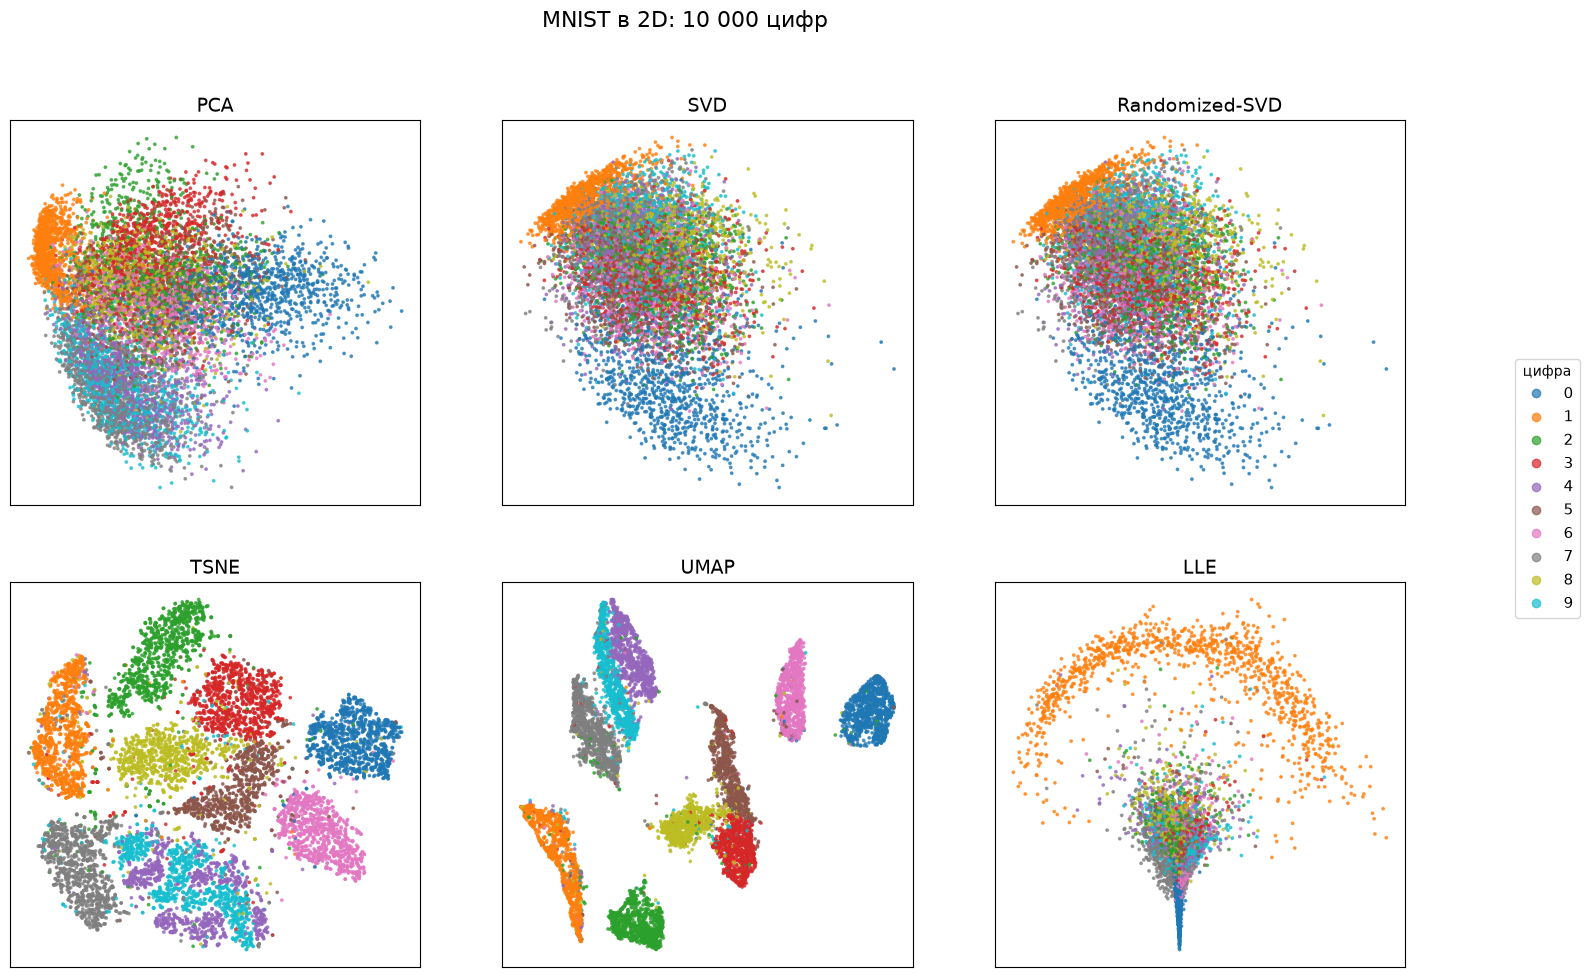

In [82]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, (name, points) in zip(axes.ravel(), embeddings.items()):
    scatter = ax.scatter(points[:, 0], points[:, 1], c=y_digits, cmap='tab10', s=3, alpha=0.7)
    ax.set_title(name, fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])

# одна общая легенда с цифрами для всех графиков
fig.legend(*scatter.legend_elements(), title='цифра', loc='center right', fontsize=11)
plt.suptitle('MNIST в 2D: 10 000 цифр', fontsize=16)
plt.show()

#### ⬇️ Задание 3.4. *Предложите метрики и сравните модели по тому, насколько хорошо они разделяют классы цифр.*

Берём две метрики, которые считаются по 2D-точкам и настоящим меткам цифр:

- **Силуэт (`silhouette_score`)**, от -1 до 1. Для каждой точки сравнивается среднее расстояние до своих
  (той же цифры) и до ближайшей чужой группы. Близко к 1 – группы плотные и далеко друг от друга, около 0 –
  группы перемешаны.
- **Точность KNN в 2D.** Обучаем классификатор 5 ближайших соседей на двух координатах и смотрим точность
  на кросс-валидации из 5 частей. Метрика отвечает на вопрос: можно ли по положению точки на картинке
  угадать цифру? Она не требует, чтобы группы были круглыми, достаточно, чтобы они не пересекались.

Время сжатия тоже добавляем в таблицу.

In [83]:
separation_rows = []
for name, points in embeddings.items():
    knn_accuracy = cross_val_score(KNeighborsClassifier(n_neighbors=5), points, y_digits, cv=5).mean()
    separation_rows.append({'метод': name,
                            'силуэт': silhouette_score(points, y_digits),
                            'точность KNN': knn_accuracy,
                            'время, с': reduce_times[name]})

separation = pd.DataFrame(separation_rows).set_index('метод').sort_values('точность KNN', ascending=False)
display(separation.round(3))

,силуэт,точность KNN,"время, с"
метод,,,
TSNE,0.320,0.943,16.944
UMAP,0.407,0.936,7.523
PCA,0.019,0.413,0.262
LLE,-0.078,0.408,29.224
Randomized-SVD,-0.036,0.294,0.328
SVD,-0.036,0.293,0.189


**Вывод:**  
Лучше всех цифры разделяют **t-SNE** (точность KNN 94 %) и **UMAP** (94 %, лучший силуэт 0.41).
PCA, SVD, Randomized-SVD и LLE оставляют большую часть цифр перемешанной (точность 29-41 %). SVD хуже PCA,
потому что не центрирует данные (см. 1.2).

### ⬇️ Сдача работы. *Сохраните одну из моделей из части «Визуализации». Ваш проверяющий загрузит её и с её помощью сожмёт одну из рукописных цифр. Сжатый вектор должен иметь те же значения. Подготовьте фрагмент кода, который показывает, как загрузить модель, как её применить и какими должны быть результаты.*

Сохраняем **PCA**: у него есть метод `transform`, и он всегда даёт одинаковый результат для одной и той же
картинки. t-SNE и LLE так не умеют (t-SNE вообще не может сжать новую точку), а UMAP привязан к версии
библиотеки и считает приближённо. Модель сохраняется стандартным модулем `pickle` в файл `pca_mnist.pkl`
рядом с ноутбуком. Туда же кладём цифру для проверки – `digit_7.npy`, чтобы проверяющему не понадобился
датасет MNIST.

In [84]:
# сохраняем обученную модель PCA из задания 3.3
with open('pca_mnist.pkl', 'wb') as file:
    pickle.dump(reducers['PCA'], file)

# первая цифра тестового файла MNIST – её сожмёт проверяющий, поэтому кладём её рядом с моделью
test_images, test_labels = read_mnist(DATA_DIR + 'mnist/t10k-images-idx3-ubyte.gz',
                                      DATA_DIR + 'mnist/t10k-labels-idx1-ubyte.gz')
np.save('digit_7.npy', test_images[0])

print('Модель сохранена в pca_mnist.pkl')
print('Цифра для проверки сохранена в digit_7.npy, метка:', test_labels[0])

Модель сохранена в pca_mnist.pkl
Цифра для проверки сохранена в digit_7.npy, метка: 7


Фрагмент для проверяющего. Он не зависит ни от остального ноутбука, ни от датасета: нужны только два файла
из `src` – модель `pca_mnist.pkl` и `digit_7.npy` (**первая цифра тестового файла MNIST**, это семёрка).
Ячейку можно запустить сразу после `git clone`.

In [85]:
import pickle
import numpy as np
import sklearn

print('Версия scikit-learn:', sklearn.__version__)

# 1. загружаем модель
with open('pca_mnist.pkl', 'rb') as file:
    loaded_pca = pickle.load(file)

# 2. загружаем цифру 28x28 (яркость 0..255) и превращаем её в вектор 0..1 – так же, как в задании 3.2
digit = np.load('digit_7.npy')
digit_vector = digit.reshape(1, -1) / 255

# 3. сжимаем цифру до двух чисел
compressed = loaded_pca.transform(digit_vector)
print('Сжатый вектор:', compressed.round(6))

Версия scikit-learn: 1.9.1
Сжатый вектор: [[-1.330389 -2.910253]]


Ожидаемый результат: `Сжатый вектор: [[-1.330389 -2.910253]]`. Если модель загружена правильно,
проверяющий получит те же два числа (возможны расхождения лишь в последних знаках из-за разных версий numpy).

Модель сохранена в scikit-learn 1.9.1. С другой версией sklearn при загрузке может появиться предупреждение
`InconsistentVersionWarning` – при близких версиях числа всё равно совпадают (проверено на 1.9.0).

---

### ⬇️ Задание 4. *Сжатие изображений с помощью SVD*

#### ⬇️ Задание 4.1. *Выберите 3 случайных изображения в оттенках серого и загрузите их в матрицу с помощью Python.*

Берём три картинки из набора тестовых изображений scikit-image: астронавт, чашка кофе и кот. Они лежат в
`datasets/images/`. Картинки цветные, поэтому при загрузке переводим их в оттенки серого через
`convert('L')` из Pillow. Получается матрица, где каждое число – яркость пикселя от 0 до 255.

astronaut  матрица (512, 512)
coffee     матрица (400, 600)
chelsea    матрица (300, 451)


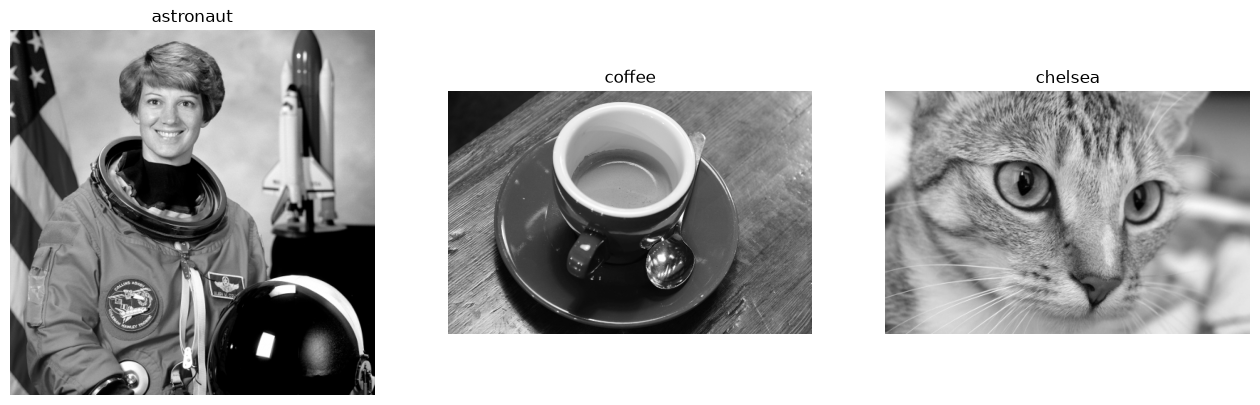

In [86]:
image_names = ['astronaut', 'coffee', 'chelsea']

# каждая картинка – матрица яркостей (строки – строки пикселей, столбцы – столбцы пикселей)
images = {}
for name in image_names:
    gray = Image.open(DATA_DIR + f'images/{name}.png').convert('L')
    images[name] = np.array(gray, dtype=float)
    print(f'{name:10} матрица {images[name].shape}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, matrix) in zip(axes, images.items()):
    ax.imshow(matrix, cmap='gray')
    ax.set_title(name)
    ax.axis('off')
plt.show()

#### ⬇️ Задание 4.2. *Разложите матрицу с помощью SVD.*

Раскладываем каждую матрицу через `np.linalg.svd`. Функция возвращает три части в том же порядке, что и в
формуле $F = V D U^T$: матрицу $V$, вектор $d$ с числами на диагонали $D$ и матрицу $U^T$. Параметр `full_matrices=False` оставляет только нужную
часть матриц: $r = \min(n, m)$ столбцов у $V$ и строк у $U^T$. Перемножив всё обратно, проверяем, что
разложение точное.

In [87]:
svd_parts = {}
for name, matrix in images.items():
    V, d, Ut = np.linalg.svd(matrix, full_matrices=False)
    svd_parts[name] = (V, d, Ut)

    # обратное перемножение должно дать исходную картинку
    restored = V @ np.diag(d) @ Ut
    print(f'{name:10} V {V.shape}, d {d.shape}, Ut {Ut.shape}, '
          f'восстановление точное: {np.allclose(restored, matrix)}')

astronaut  V (512, 512), d (512,), Ut (512, 512), восстановление точное: True
coffee     V (400, 400), d (400,), Ut (400, 600), восстановление точное: True
chelsea    V (300, 300), d (300,), Ut (300, 451), восстановление точное: True


#### ⬇️ Задание 4.3. *Меняя ранг, вычислите приближение исходной матрицы низкого ранга и постройте восстановленное изображение. Используйте до 10 разных рангов. Как выглядит спектр сингулярных чисел и сколько мод нужно для хорошего восстановления изображения?*

Приближение ранга k – это произведение первых k столбцов $V$, первых k чисел $d$ (диагональ $D$) и первых k строк
$U^T$. Берём 9 рангов от 1 до 200 и десятой картинкой ставим оригинал.

Под каждой картинкой подписываем **относительную ошибку** – норму Фробениуса разницы с оригиналом, делённую
на норму оригинала. Так ошибки разных картинок можно сравнивать между собой.

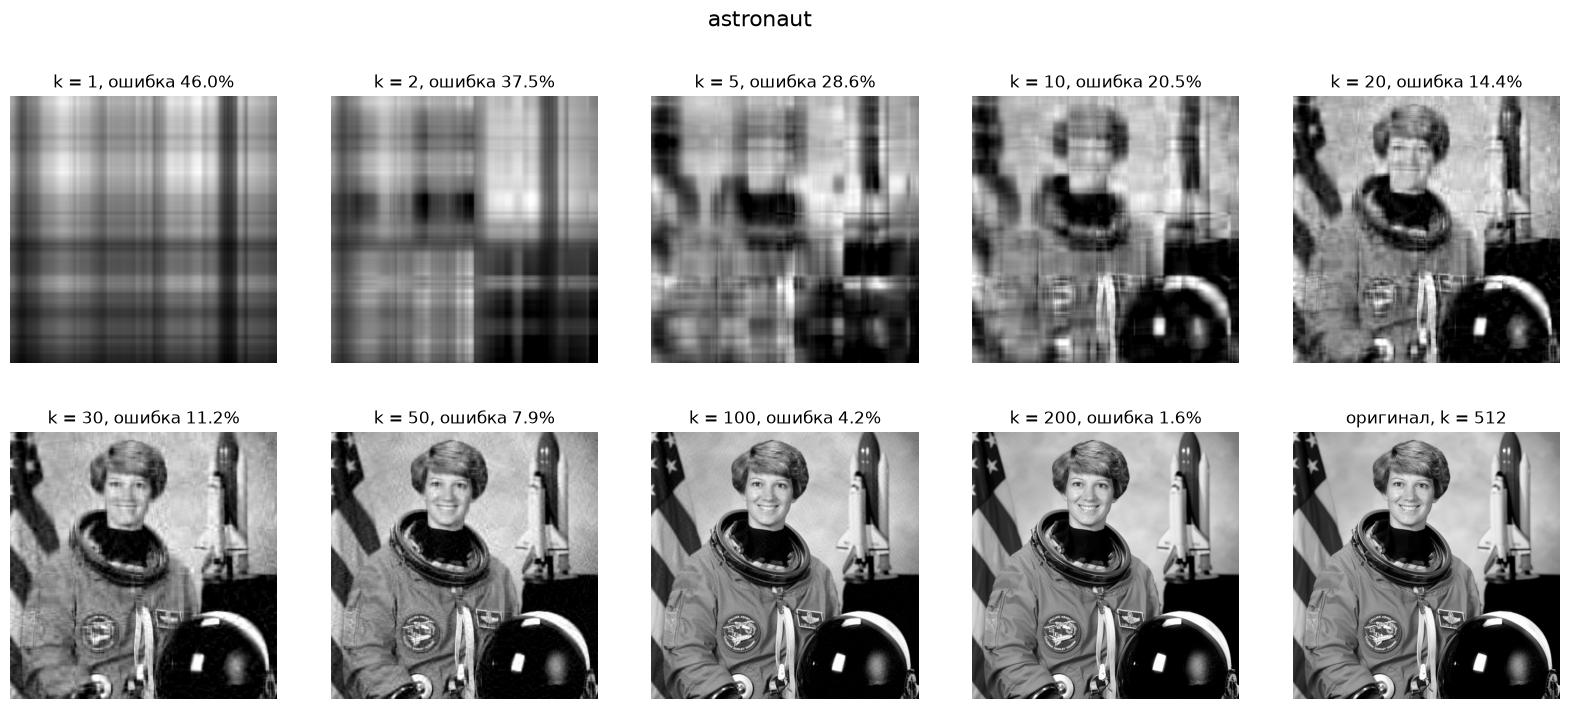

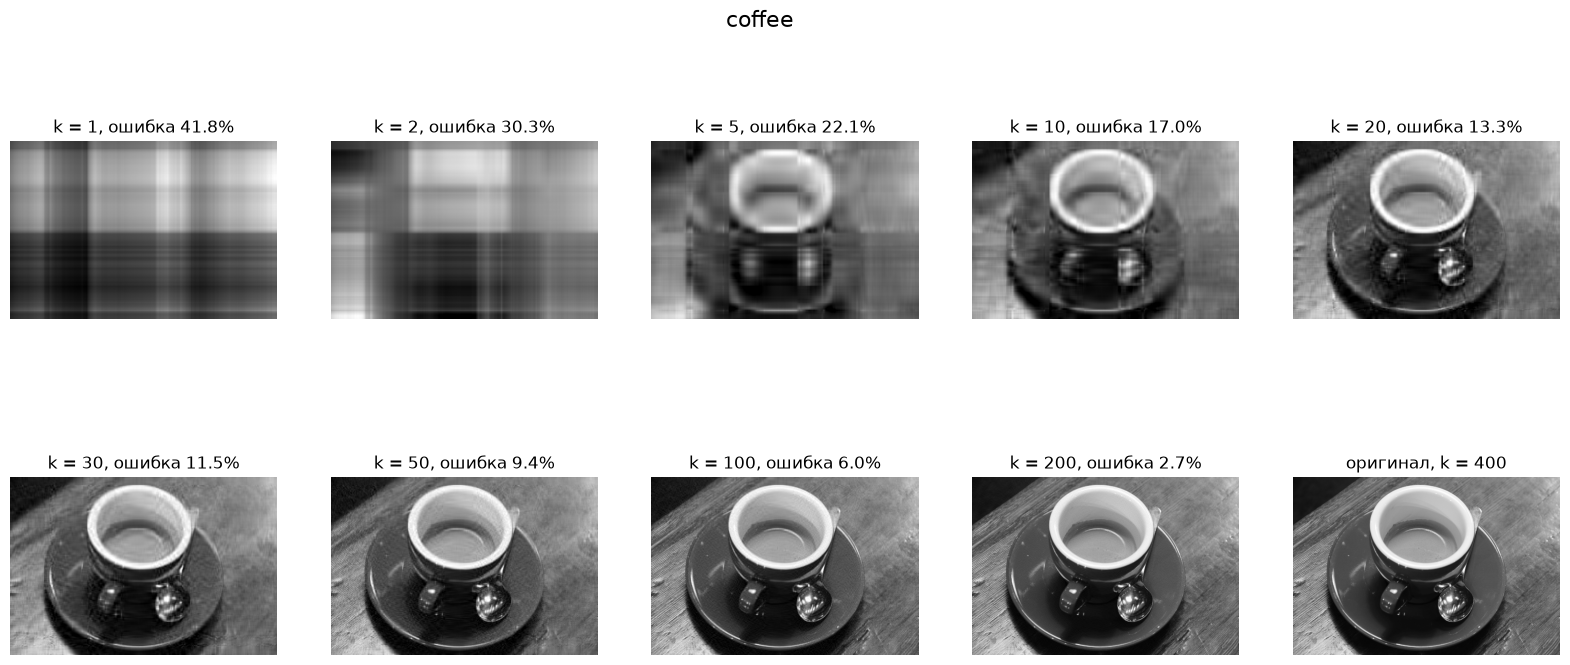

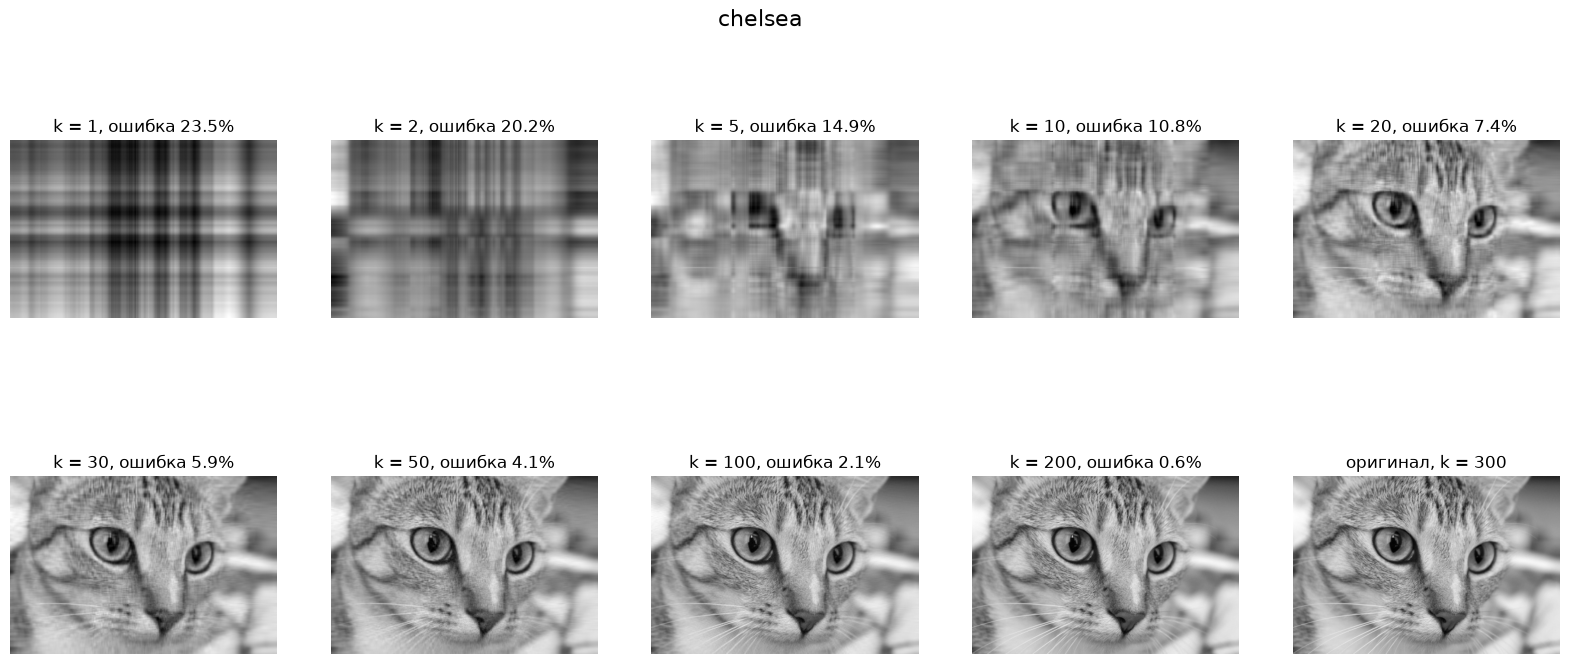

In [88]:
RANKS = [1, 2, 5, 10, 20, 30, 50, 100, 200]


def low_rank(V, d, Ut, k):
    '''Приближение ранга k: первые k столбцов V, первые k чисел d и первые k строк Ut'''
    return V[:, :k] @ np.diag(d[:k]) @ Ut[:k, :]


for name, matrix in images.items():
    V, d, Ut = svd_parts[name]
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))

    for ax, k in zip(axes.ravel(), RANKS):
        approx = low_rank(V, d, Ut, k)
        error = np.linalg.norm(matrix - approx) / np.linalg.norm(matrix)
        ax.imshow(np.clip(approx, 0, 255), cmap='gray')
        ax.set_title(f'k = {k}, ошибка {error:.1%}')
        ax.axis('off')

    # последняя клетка – оригинал для сравнения
    axes[1, 4].imshow(matrix, cmap='gray')
    axes[1, 4].set_title(f'оригинал, k = {len(d)}')
    axes[1, 4].axis('off')

    plt.suptitle(name, fontsize=16)
    plt.show()

Спектр сингулярных чисел – это сами числа $d_1 \ge d_2 \ge \dots$ с диагонали $D$ по порядку. Они убывают очень
быстро, поэтому ось Y делаем логарифмической.

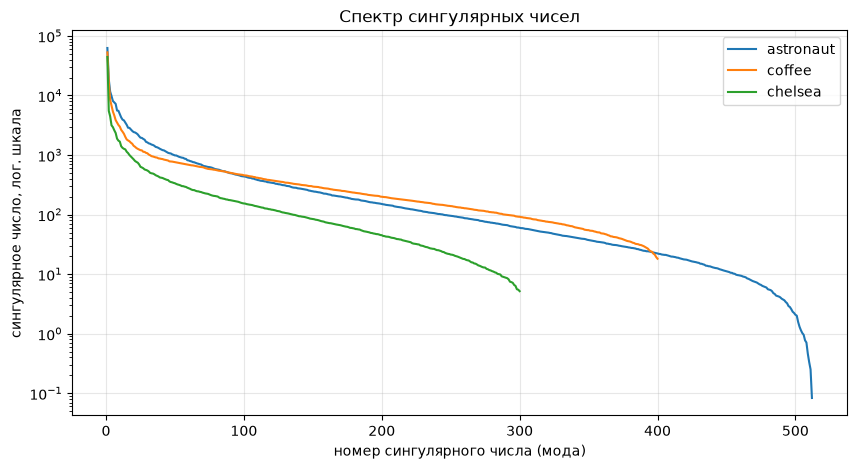

astronaut  d_1 / d_10 =  12.9, d_1 / d_100 =  143.3
coffee     d_1 / d_10 =  17.6, d_1 / d_100 =  115.9
chelsea    d_1 / d_10 =  26.3, d_1 / d_100 =  287.9


In [89]:
plt.figure(figsize=(10, 5))
for name in image_names:
    d = svd_parts[name][1]
    plt.plot(np.arange(1, len(d) + 1), d, label=name)

plt.yscale('log')
plt.xlabel('номер сингулярного числа (мода)')
plt.ylabel('сингулярное число, лог. шкала')
plt.title('Спектр сингулярных чисел')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# во сколько раз первое число больше десятого и сотого
for name in image_names:
    d = svd_parts[name][1]
    print(f'{name:10} d_1 / d_10 = {d[0] / d[9]:5.1f}, d_1 / d_100 = {d[0] / d[99]:6.1f}')

#### ✔️ Ответ на вопросы 4.3

**Спектр сингулярных чисел** спадает очень круто: первое число в 13-26 раз больше десятого и в 115-290 раз
больше сотого, дальше кривая уходит в длинный пологий «хвост». Первые моды несут общую форму и крупные
пятна света и тени, а хвост – мелкие детали и шум.

**Сколько мод нужно.** По картинкам видно:
- при k = 1-5 картинка превращается в «клетчатую» сетку из полос – это произведения отдельных столбцов и строк;
- при k = 20-30 уже узнаётся сюжет, но остаётся рябь;
- при **k = 50-100** изображение выглядит почти как оригинал (ошибка у астронавта 8 % и 4 %), а при k = 200
  отличий на глаз не видно.

Итого для хорошего восстановления хватает **примерно 50-100 мод** из 300-512. Хранить при этом нужно
$k(n + m + 1)$ чисел вместо $n \cdot m$: для астронавта при k = 50 это около 20 % от исходного объёма.

#### ⬇️ Задание 4.4. *Постройте распределение объяснённой дисперсии в зависимости от ранга. Объясните, что такое «объяснённая дисперсия».*

**Объяснённая дисперсия** показывает, какую долю разброса данных сохраняют первые k компонент. Квадрат
сингулярного числа $d_i^2$ – это разброс, который приходится на i-ю компоненту, а сумма всех
$d_i^2$ – весь разброс. Доля одной компоненты равна $d_i^2 / \sum d_j^2$,
а накопленная доля первых k компонент показывает, сколько информации сохранит приближение ранга k.

Важная деталь (та же, что в задании 1.2): дисперсия – это разброс **вокруг среднего**, поэтому столбцы
матрицы нужно сначала центрировать. Без центрирования первая компонента просто запоминает среднюю яркость
картинки и забирает себе 80-95 % «объяснённой» доли, хотя приближение ранга 1 – это размытое пятно.
Ниже считаем честную объяснённую дисперсию по центрированной матрице и для сравнения печатаем долю
первой компоненты без центрирования.

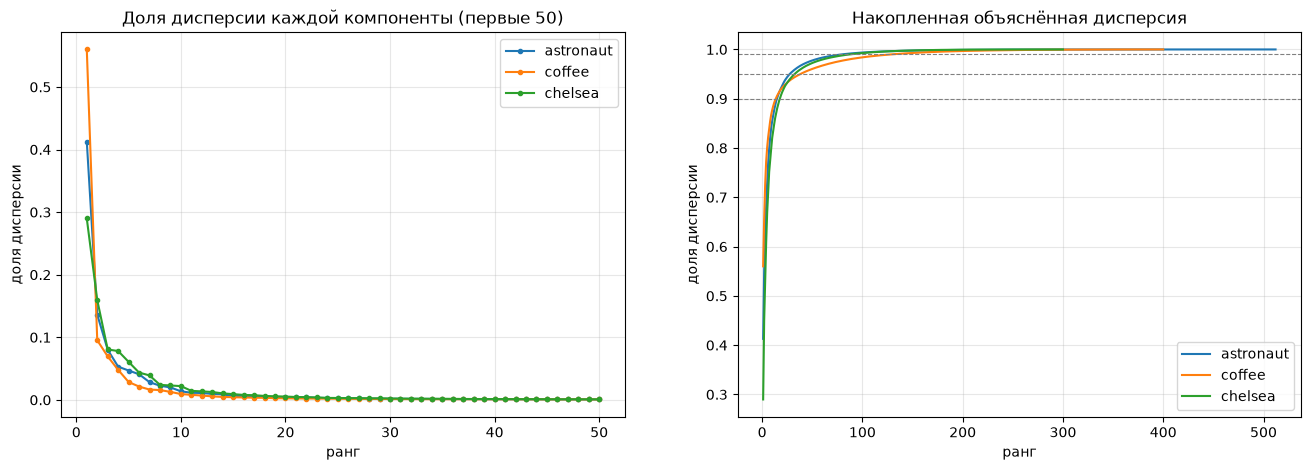

,ранг для 90 %,ранг для 95 %,ранг для 99 %,доля 1-й компоненты без центрирования
картинка,,,,
astronaut,15,28,80,0.789
coffee,14,38,129,0.825
chelsea,18,33,88,0.945


In [90]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
variance_rows = []

for name, matrix in images.items():
    # центрируем столбцы и считаем только сингулярные числа
    centered = matrix - matrix.mean(axis=0)
    d_centered = np.linalg.svd(centered, compute_uv=False)
    ratio = d_centered ** 2 / np.sum(d_centered ** 2)
    cumulative = np.cumsum(ratio)
    ranks = np.arange(1, len(ratio) + 1)

    axes[0].plot(ranks[:50], ratio[:50], marker='.', label=name)
    axes[1].plot(ranks, cumulative, label=name)

    # доля первой компоненты без центрирования – для сравнения
    d_raw = svd_parts[name][1]
    variance_rows.append({'картинка': name,
                          'ранг для 90 %': int(np.argmax(cumulative >= 0.90)) + 1,
                          'ранг для 95 %': int(np.argmax(cumulative >= 0.95)) + 1,
                          'ранг для 99 %': int(np.argmax(cumulative >= 0.99)) + 1,
                          'доля 1-й компоненты без центрирования': d_raw[0] ** 2 / np.sum(d_raw ** 2)})

axes[0].set_title('Доля дисперсии каждой компоненты (первые 50)')
axes[0].set_xlabel('ранг')
axes[0].set_ylabel('доля дисперсии')
axes[1].set_title('Накопленная объяснённая дисперсия')
axes[1].set_xlabel('ранг')
axes[1].set_ylabel('доля дисперсии')
for level in [0.90, 0.95, 0.99]:
    axes[1].axhline(level, color='grey', linestyle='--', linewidth=0.8)
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

display(pd.DataFrame(variance_rows).set_index('картинка').round(3))

#### ✔️ Вывод по заданию 4

**90 % разброса картинки сохраняют 14-18 компонент**, 99 % – 80-130. Объяснённую дисперсию считаем
по центрированной матрице: без центрирования первая компонента забирает 79-95 % только за счёт средней
яркости.

---

### ⬇️ Задание 5. *Выделение фона с помощью SVD*

#### ⬇️ Задание 5.1. *Загрузите «Video_008.avi».*

Видео взято из архива `bmc_real.zip` (на сайте его можно скачать и отдельно – `Video_008.zip`) и лежит в
`datasets/`. Читаем его кадр за кадром через `cv2.VideoCapture` и сразу переводим каждый кадр в оттенки
серого – для выделения фона цвет не нужен, а матрица станет в 3 раза меньше.

In [91]:
video = cv2.VideoCapture(DATA_DIR + 'Video_008.avi')
frames = []
while True:
    success, frame = video.read()    # success станет False, когда кадры закончатся
    if not success:
        break
    frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
video.release()

frame_height, frame_width = frames[0].shape
print('Кадров:', len(frames))
print('Размер кадра:', frame_height, 'x', frame_width)

Кадров: 792
Размер кадра: 240 x 320


#### ⬇️ Задание 5.2. *Представьте видео в виде матрицы и разложите её с помощью SVD.*

Каждый кадр разворачиваем в вектор и ставим **столбцом** матрицы: строка – пиксель, столбец – момент
времени. Фон почти не меняется, поэтому все столбцы очень похожи друг на друга, и матрица должна хорошо
приближаться матрицей низкого ранга. Движущиеся машины и люди – это небольшие отклонения от этого
общего фона.

In [92]:
# строки – пиксели, столбцы – кадры
video_matrix = np.column_stack([frame.ravel() for frame in frames]).astype(float)
print('Матрица видео:', video_matrix.shape)

V_video, d_video, Ut_video = np.linalg.svd(video_matrix, full_matrices=False)
print('V:', V_video.shape, '| d:', d_video.shape, '| Ut:', Ut_video.shape)

energy = d_video ** 2 / np.sum(d_video ** 2)
print(f'Доля первой компоненты: {energy[0]:.2%}')
print('Первые 5 сингулярных чисел:', d_video[:5].round(0))

Матрица видео: (76800, 792)
V: (76800, 792) | d: (792,) | Ut: (792, 792)
Доля первой компоненты: 98.09%
Первые 5 сингулярных чисел: [986590.  90909.  23168.  22810.  20587.]


#### ⬇️ Задание 5.3. *Восстановите первый кадр с помощью приближения низкого ранга. Какой ранг нужно использовать, чтобы получить фон?*

Восстанавливаем всю матрицу видео рангами 1, 2, 5 и 10, берём из неё первый столбец (первый кадр) и
разворачиваем обратно в картинку. Нижний ряд – разница между настоящим кадром и приближением: если
приближение – это фон, в разнице останутся только движущиеся объекты.

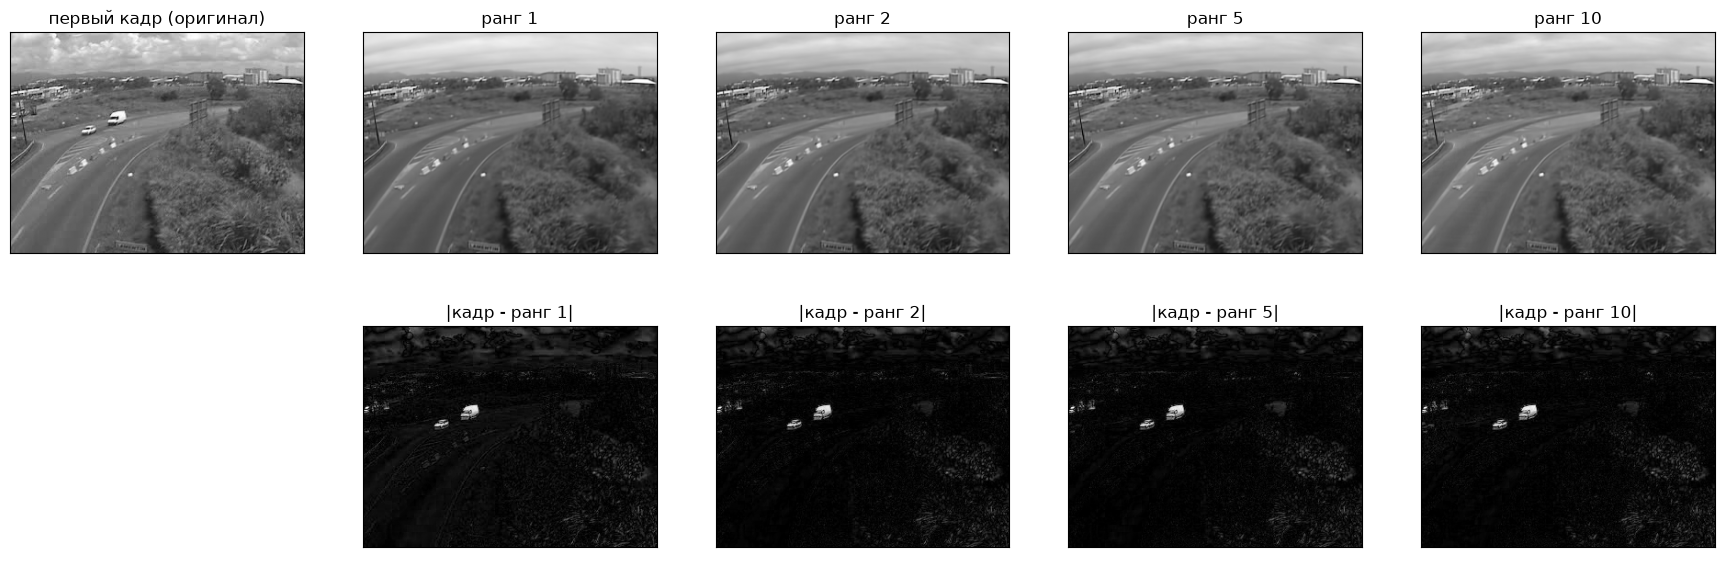

In [93]:
first_frame = video_matrix[:, 0].reshape(frame_height, frame_width)
video_ranks = [1, 2, 5, 10]

fig, axes = plt.subplots(2, 5, figsize=(22, 7))
axes[0, 0].imshow(first_frame, cmap='gray')
axes[0, 0].set_title('первый кадр (оригинал)')
axes[1, 0].axis('off')

for col, k in enumerate(video_ranks, start=1):
    # первый столбец приближения ранга k = первый кадр без мелких деталей
    approx = V_video[:, :k] @ np.diag(d_video[:k]) @ Ut_video[:k, 0]
    background = approx.reshape(frame_height, frame_width)
    axes[0, col].imshow(np.clip(background, 0, 255), cmap='gray')
    axes[0, col].set_title(f'ранг {k}')
    axes[1, col].imshow(np.abs(first_frame - background), cmap='gray')
    axes[1, col].set_title(f'|кадр - ранг {k}|')

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

#### ✔️ Вывод по заданию 5

**Для выделения фона достаточно ранга 1**: на первую компоненту приходится 98 % энергии видео.
Машины в каждом месте кадра бывают недолго и в фон не попадают – они остаются только в разнице
`|кадр - ранг 1|`.